# Lab6 Report: 
## German-to-English Translation with Attention-Mechanism Transformer Model

In [1]:
%matplotlib inline

import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd 
import seaborn as sns
from typing import Iterable, List
from timeit import default_timer as timer

import torch
import torch.nn as nn
from torch.nn import Transformer
from torch import Tensor

from torchtext.data.utils import get_tokenizer
from torchtext.vocab import build_vocab_from_iterator
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence

# Initialize your numpy and pytorch random seeds for reproducibility 
np.random.seed(0)
torch.manual_seed(0)

# Create a torch.device object to tell pytorch where to store your tensors: cpu or gpu
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Training device: {DEVICE}")

/home/dfredin/miniconda3/envs/phys575/lib/python3.10/site-packages/torchtext/data/__init__.py:4: UserWarning: 
/!\ IMPORTANT WARNING ABOUT TORCHTEXT STATUS /!\ 
Torchtext is deprecated and the last released version will be 0.18 (this one). You can silence this warning by calling the following at the beginnign of your scripts: `import torchtext; torchtext.disable_torchtext_deprecation_warning()`
  warnings.warn(torchtext._TORCHTEXT_DEPRECATION_MSG)
/home/dfredin/miniconda3/envs/phys575/lib/python3.10/site-packages/torchtext/vocab/__init__.py:4: UserWarning: 
/!\ IMPORTANT WARNING ABOUT TORCHTEXT STATUS /!\ 
Torchtext is deprecated and the last released version will be 0.18 (this one). You can silence this warning by calling the following at the beginnign of your scripts: `import torchtext; torchtext.disable_torchtext_deprecation_warning()`
  warnings.warn(torchtext._TORCHTEXT_DEPRECATION_MSG)
/home/dfredin/miniconda3/envs/phys575/lib/python3.10/site-packages/torchtext/utils.py:4: UserWa

Training device: cuda


In [2]:
from IPython.display import Image # For displaying images in colab jupyter cell

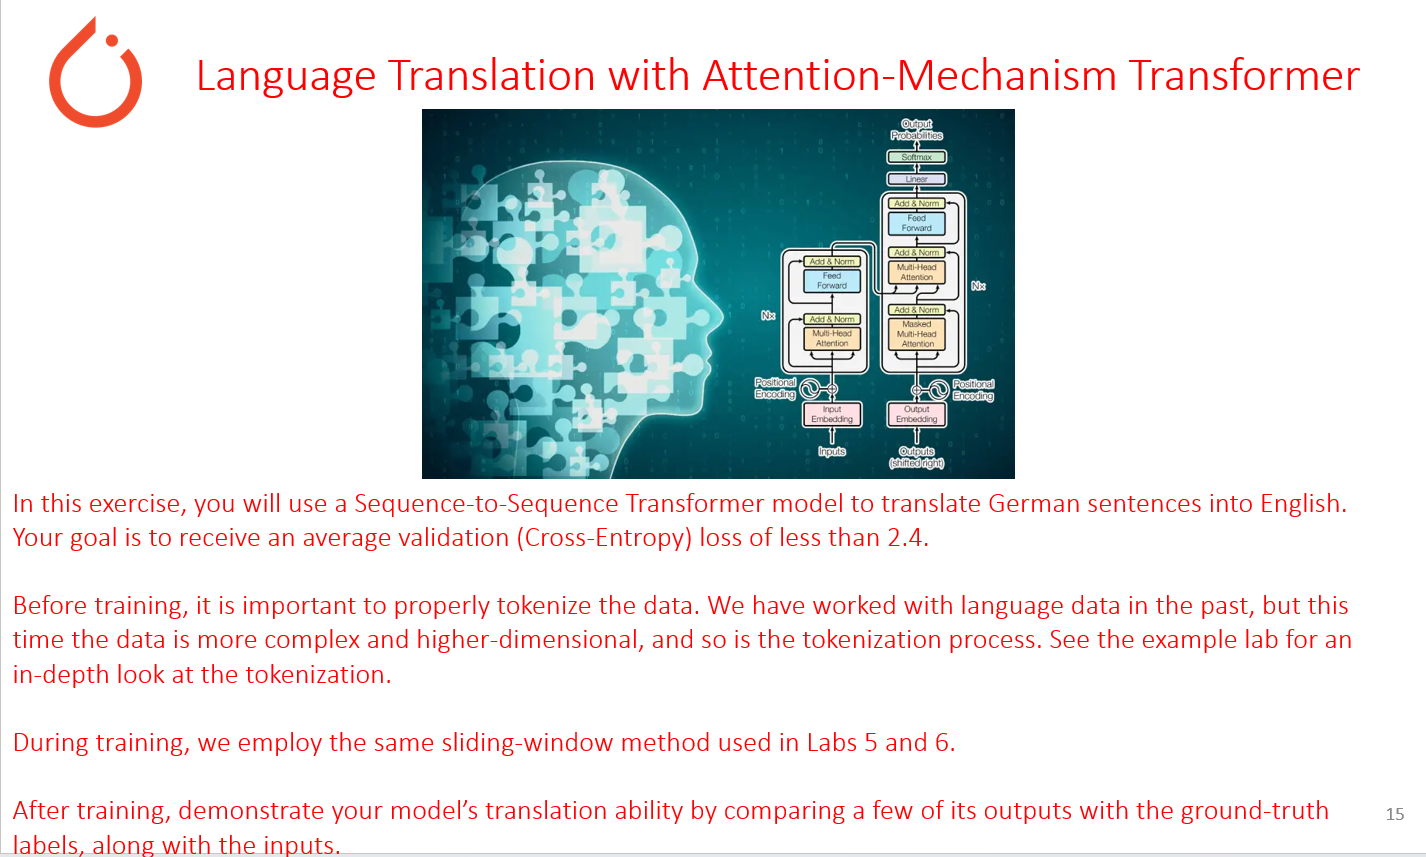

In [3]:
Image('lab6_exercise.png', width = 1000)

In [4]:
# Seaborn plot styling
sns.set(style = 'white', font_scale = 2)

## Download data

In [5]:
# Load the data and store it as a list of tuples: each element in the list should be a tuple of the form (german_sentence, english_sentence)
text_pairs = []
with open('de_to_en.txt', 'r', encoding='utf-8') as f:
    for line in f:
        fields = line.rstrip('\r\n').split('\t')
        if len(fields) >= 2 and fields[0].strip() and fields[1].strip():
            text_pairs.append((fields[0].strip(), fields[1].strip()))
print(f"Loaded {len(text_pairs)} German-English sentence pairs")

Loaded 31014 German-English sentence pairs


## Let's see what the data looks like

In [6]:
# Print the first ten translated lines
for german, english in text_pairs[:10]:
    print(f"German: {german} | English: {english}")

German: Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche. | English: Two young, White males are outside near many bushes.
German: Mehrere Männer mit Schutzhelmen bedienen ein Antriebsradsystem. | English: Several men in hard hats are operating a giant pulley system.
German: Ein kleines Mädchen klettert in ein Spielhaus aus Holz. | English: A little girl climbing into a wooden playhouse.
German: Ein Mann in einem blauen Hemd steht auf einer Leiter und putzt ein Fenster. | English: A man in a blue shirt is standing on a ladder cleaning a window.
German: Zwei Männer stehen am Herd und bereiten Essen zu. | English: Two men are at the stove preparing food.
German: Ein Mann in grün hält eine Gitarre, während der andere Mann sein Hemd ansieht. | English: A man in green holds a guitar while the other man observes his shirt.
German: Ein Mann lächelt einen ausgestopften Löwen an. | English: A man is smiling at a stuffed lion
German: Ein schickes Mädchen spricht mit dem Handy währ

## Create source and target language tokenizers

But first, what exactly is a *tokenizer*?

A short but incomplete summary is that a tokenizer converts your text/string into a list of numerical values (a list of *tokens*). We performed tokenization in Lab 5 when we converted each alphanumeric character in our text into a number (an index in a dictionary). 

Here, the tokenization is a bit different. Instead of converting each *character* into a number, we want to convert each *word* into a number. As you can imagine, this means the vocabulary of our dataset - the set of unique tokens it contains - will be much larger. There are many more words in English than there are letters! This also means the value of each token will be more unique and meaningful.

Part of tokenizing at the word level is the process of standardizing the text by converting it to lowercase, removing punctuation or special characters, and dealing with contractions or other language-specific features. This is sometimes called *stemming*, reflecting the fact that we want to only extract the *essential meaning* of each word - the "stem" - not necessarily the punctuation, prefixes, suffixes, etc. surrounding it.

Luckily for us, there are some existing Python packages that do this automatically. The below cell downloads two different tokenizers (one each for the source and larget languages), and assigns them to appropriate keys within the "token_transform" dictionary. 
In Lab 5, you performed tokenization when you converted each character of the text into a specific number.

In [7]:
# Define MACRO - a high-level variable that won't change throughout the duration of the code - for your source and target languages
SRC_LANGUAGE = 'de'
TGT_LANGUAGE = 'en' 


# Download the German and English tokenizers, and assign them to appropriate keys in your token_transform dictionary
token_transform = {}
token_transform[SRC_LANGUAGE] = get_tokenizer('spacy', language='de_core_news_sm')
token_transform[TGT_LANGUAGE] = get_tokenizer('spacy', language='en_core_web_sm')

## Let's see what these specific tokenizers do.

In [8]:
# Tokenize the first line of each dataset, and print the tokenized version of it
de_0_tokenized = token_transform[SRC_LANGUAGE](text_pairs[0][0])
en_0_tokenized = token_transform[TGT_LANGUAGE](text_pairs[0][1])
print("German tokens:", de_0_tokenized)
print("English tokens:", en_0_tokenized)

German tokens: ['Zwei', 'junge', 'weiße', 'Männer', 'sind', 'im', 'Freien', 'in', 'der', 'Nähe', 'vieler', 'Büsche', '.']
English tokens: ['Two', 'young', ',', 'White', 'males', 'are', 'outside', 'near', 'many', 'bushes', '.']


## Create a vocabulary for each language's dataset

In Lab 5, we did this with a simple dictionary that mapped each character to an integer (and vice versa). However, PyTorch has a built-in dictionary object that provides some extra functionality. 

We will create this object using torchtext.data.build_vocab_from_iterator(). This function takes an iterator as input and returns a torchtext.vocab.Vocab object. This is a dictionary-like object that maps tokens to indices, but where it differs from a normal dictionary, is that its indices are assigned based on the frequency of the tokens in the dataset. For example, the most frequent token gets the index 0, the second most frequent gets the index 1, and so on. This frequency-index mapping saves a bunch of compute time and resources. 


Moreover, this time we will also have the four "special" tokens, that will always be assigned to the first four indices.

In [9]:
# Define a helper function that converts a list of strings into a list of lists-of-tokens
def yield_tokens(data_iter, language):
    language_index = {SRC_LANGUAGE: 0, TGT_LANGUAGE: 1}
    for data_sample in data_iter:
        yield token_transform[language](data_sample[language_index[language]])

# Define your special tokens and their indeces in your vocabulary
special_tokens = ['<unk>', '<pad>', '<bos>', '<eos>']
UNK_IDX, PAD_IDX, BOS_IDX, EOS_IDX = 0, 1, 2, 3

# Define your vocabulary for each language using the build_vocab_from_iterator function
# Use the same seeded permutation in the split cell below so that the
# vocabularies learn ONLY from training sentences (no test/validation leakage).
split_indices = np.random.permutation(len(text_pairs))
n_train = int(0.70 * len(text_pairs))
train_pairs_for_vocab = [text_pairs[i] for i in split_indices[:n_train]]

vocab_transform = {}
for language in [SRC_LANGUAGE, TGT_LANGUAGE]:
    vocab_transform[language] = build_vocab_from_iterator(
        yield_tokens(train_pairs_for_vocab, language),
        min_freq=1, specials=special_tokens, special_first=True
    )

# Set ``UNK_IDX`` as the default index. 
for language in [SRC_LANGUAGE, TGT_LANGUAGE]:
    vocab_transform[language].set_default_index(UNK_IDX)

# Let's see the first 20 words in each vocabulary
print("First 20 German vocabulary entries:", vocab_transform[SRC_LANGUAGE].get_itos()[:20])
print("First 20 English vocabulary entries:", vocab_transform[TGT_LANGUAGE].get_itos()[:20])

First 20 German vocabulary entries: ['<unk>', '<pad>', '<bos>', '<eos>', '.', 'Ein', 'einem', 'in', 'und', 'mit', 'auf', ',', 'Mann', 'einer', 'Eine', 'ein', 'der', 'Frau', 'eine', 'die']
First 20 English vocabulary entries: ['<unk>', '<pad>', '<bos>', '<eos>', 'a', '.', 'A', 'in', 'the', 'on', 'and', 'is', 'man', 'of', 'with', ',', 'woman', 'are', 'to', 'Two']


## Train-Validate-Test split

In [10]:
# Shuffle the text pairs
text_pairs = [text_pairs[i] for i in split_indices]

# Let's go for a 70-20-10 train-val-test split
n_train = int(0.70 * len(text_pairs))
train_pairs = text_pairs[:n_train]

n_val = int(0.20 * len(text_pairs))
val_pairs = text_pairs[n_train:n_train + n_val]

test_pairs = text_pairs[n_train + n_val:]

# Check the size of each data set
print(f"{len(text_pairs)} total pairs")
print(f"{len(train_pairs)} training pairs")
print(f"{len(val_pairs)} validation pairs")
print(f"{len(test_pairs)} test pairs")
assert len(text_pairs) == len(train_pairs) + len(val_pairs) + len(test_pairs)

31014 total pairs
21709 training pairs
6202 validation pairs
3103 test pairs


### Mask functions

The mask function plays an essential role in the training of a transformer model, specifically during the pre-training phase when the model learns to understand and generate language. The two main purposes of the mask function are:

1. To facilitate self-attention mechanism: Transformers use self-attention mechanisms to identify relationships between words in a sequence. Masking is used to prevent the model from "cheating" by looking at future tokens when trying to predict the current token. In other words, the mask function ensures that the model only attends to the current token and the previous tokens, not the future tokens, during the training process.

2. To enable masked language modeling (MLM): Masked language modeling is a popular pre-training objective used in transformer-based models like BERT. In MLM, a certain percentage of input tokens are randomly masked (usually around 15%), and the model is tasked with predicting the original tokens at these masked positions. The mask function serves as a way of hiding the original token from the model, forcing it to learn contextual representations that can help it predict the masked tokens accurately.

The use of the mask function in both self-attention and MLM helps the transformer model learn meaningful context-dependent representations, making it more effective at understanding and generating natural language.

In [11]:
# Define your masking function
def generate_square_subsequent_mask(sz):
    # Boolean attention masks: True blocks attention to future tokens.
    return torch.triu(torch.ones((sz, sz), dtype=torch.bool, device=DEVICE), diagonal=1)


def create_mask(src, tgt):
    src_seq_len = src.shape[0]
    tgt_seq_len = tgt.shape[0]
    src_mask = torch.zeros((src_seq_len, src_seq_len), dtype=torch.bool, device=DEVICE)
    tgt_mask = generate_square_subsequent_mask(tgt_seq_len)
    src_padding_mask = (src == PAD_IDX).transpose(0, 1)
    tgt_padding_mask = (tgt == PAD_IDX).transpose(0, 1)
    return src_mask, tgt_mask, src_padding_mask, tgt_padding_mask

## Collation

The collation function is what converts our strings into batches of tensors that can be processed by our model, based on the vocabularies and tokenization functions we have built up thus far. 

Again, this is something we can do manually, but at some point the data transformations get so complicated that we might as well put them all into a function. Moreover, defining our transformation as a *function* allows us to use some more built-in PyTorch functionality that makes our jobs a whole lot easier. See: torch.utils.data.DataLoader. 

In [12]:
# Define helper function to club together sequential operations
def sequential_transforms(*transforms):
    def apply_transforms(text):
        for transform in transforms:
            text = transform(text)
        return text
    return apply_transforms

# Define function to add BOS/EOS and create a tensor for input sequence indices
def tensor_transform(token_ids):
    return torch.cat((
        torch.tensor([BOS_IDX], dtype=torch.long),
        torch.tensor(token_ids, dtype=torch.long),
        torch.tensor([EOS_IDX], dtype=torch.long)
    ))

# Define your ``src`` and ``tgt`` language text transforms to convert raw strings into tensors indices
text_transform = {}
for language in [SRC_LANGUAGE, TGT_LANGUAGE]:
    text_transform[language] = sequential_transforms(
        token_transform[language], vocab_transform[language], tensor_transform
    )

# Define your "collation" function to collate data samples into batch tensors
def collate_fn(batch):
    src_batch, tgt_batch = [], []
    for src_sample, tgt_sample in batch:
        src_batch.append(text_transform[SRC_LANGUAGE](src_sample.rstrip('\n')))
        tgt_batch.append(text_transform[TGT_LANGUAGE](tgt_sample.rstrip('\n')))
    src_batch = pad_sequence(src_batch, padding_value=PAD_IDX)
    tgt_batch = pad_sequence(tgt_batch, padding_value=PAD_IDX)
    return src_batch, tgt_batch

# Define training, evaluation functions

Modularization is the name of the game.

Not only does this help us here, but if you ever need to train a similar model in the future, you can simply import the ones defined here! 

For example, imagine this was a Python script and not a notebook, and the filename was "german_to_english_transformer.py" Then, in whichever future script or notebook you wish to use these functions, you could simply call:
"from german_to_english_transformer import train_epoch, evaluate"

In [13]:
# Define a function to train the model for a single epoch
def train_epoch(model, optimizer):
    model.train()
    batch_losses = []
    total_weighted_loss = 0.0
    total_valid_tokens = 0
    train_dataloader = DataLoader(train_pairs, batch_size=BATCH_SIZE,
                                  shuffle=True, collate_fn=collate_fn)
    for src, tgt in train_dataloader:
        src, tgt = src.to(DEVICE), tgt.to(DEVICE)
        tgt_input = tgt[:-1, :]
        tgt_out = tgt[1:, :]
        src_mask, tgt_mask, src_pad, tgt_pad = create_mask(src, tgt_input)

        optimizer.zero_grad()
        logits = model(src, tgt_input, src_mask, tgt_mask, src_pad, tgt_pad, src_pad)
        loss = loss_fn(logits.reshape(-1, logits.shape[-1]), tgt_out.reshape(-1))
        loss.backward()
        optimizer.step()

        valid_tokens = (tgt_out != PAD_IDX).sum().item()
        batch_losses.append(loss.item())
        total_weighted_loss += loss.item() * valid_tokens
        total_valid_tokens += valid_tokens
    return batch_losses, total_weighted_loss / total_valid_tokens

# Define a function to evaluate the model
@torch.no_grad()
def evaluate(model, data_pairs=None):
    model.eval()
    if data_pairs is None:
        data_pairs = val_pairs
    batch_losses = []
    total_weighted_loss = 0.0
    total_valid_tokens = 0
    val_dataloader = DataLoader(data_pairs, batch_size=BATCH_SIZE,
                                shuffle=False, collate_fn=collate_fn)
    for src, tgt in val_dataloader:
        src, tgt = src.to(DEVICE), tgt.to(DEVICE)
        tgt_input = tgt[:-1, :]
        tgt_out = tgt[1:, :]
        src_mask, tgt_mask, src_pad, tgt_pad = create_mask(src, tgt_input)
        logits = model(src, tgt_input, src_mask, tgt_mask, src_pad, tgt_pad, src_pad)
        loss = loss_fn(logits.reshape(-1, logits.shape[-1]), tgt_out.reshape(-1))

        valid_tokens = (tgt_out != PAD_IDX).sum().item()
        batch_losses.append(loss.item())
        total_weighted_loss += loss.item() * valid_tokens
        total_valid_tokens += valid_tokens
    return batch_losses, total_weighted_loss / total_valid_tokens

## Define model

In [14]:
# Define the PositionalEncoding module that quantifies the relative position of words in a sentence
# Notice that this is not actually an MLP or neural network, i.e. it has no learned parameters
# it is just a function that you could represent analytically, if you wanted to
class PositionalEncoding(nn.Module):
    def __init__(self, emb_size, dropout, maxlen=5000):
        super().__init__()
        den = torch.exp(-torch.arange(0, emb_size, 2) * math.log(10000) / emb_size)
        pos = torch.arange(0, maxlen).reshape(maxlen, 1)
        pos_embedding = torch.zeros((maxlen, emb_size))
        pos_embedding[:, 0::2] = torch.sin(pos * den)
        pos_embedding[:, 1::2] = torch.cos(pos * den)
        pos_embedding = pos_embedding.unsqueeze(-2)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer('pos_embedding', pos_embedding)

    def forward(self, token_embedding: Tensor):
        return self.dropout(token_embedding + self.pos_embedding[:token_embedding.size(0), :])

# Define the TokenEmbedding module converts a tensor of vocabulary-indices into a tensor of token-embeddings
# Also not a neural network, but a lookup table
class TokenEmbedding(nn.Module):
    def __init__(self, vocab_size, emb_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_size)
        self.emb_size = emb_size

    def forward(self, tokens: Tensor):
        return self.embedding(tokens.long()) * math.sqrt(self.emb_size)

# Define the actual transformer model
# Question: What are we "transforming" between?
class Seq2SeqTransformer(nn.Module):
    def __init__(self, num_encoder_layers, num_decoder_layers, embedding_size,
                 num_heads, src_vocab_size, tgt_vocab_size,
                 dim_feedforward=512, dropout=0.1):
        super().__init__()
        self.transformer = Transformer(
            d_model=embedding_size,
            nhead=num_heads,
            num_encoder_layers=num_encoder_layers,
            num_decoder_layers=num_decoder_layers,
            dim_feedforward=dim_feedforward,
            dropout=dropout
        )
        self.generator = nn.Linear(embedding_size, tgt_vocab_size)
        self.src_tok_emb = TokenEmbedding(src_vocab_size, embedding_size)
        self.tgt_tok_emb = TokenEmbedding(tgt_vocab_size, embedding_size)
        self.positional_encoding = PositionalEncoding(embedding_size, dropout)

    def forward(self, src, trg, src_mask, tgt_mask, src_padding_mask,
                tgt_padding_mask, memory_key_padding_mask):
        src_emb = self.positional_encoding(self.src_tok_emb(src))
        tgt_emb = self.positional_encoding(self.tgt_tok_emb(trg))
        outs = self.transformer(
            src_emb, tgt_emb, src_mask, tgt_mask, None,
            src_padding_mask, tgt_padding_mask, memory_key_padding_mask
        )
        return self.generator(outs)

    def encode(self, src: Tensor, src_mask: Tensor):
        return self.transformer.encoder(
            self.positional_encoding(self.src_tok_emb(src)), src_mask
        )

    def decode(self, tgt: Tensor, memory: Tensor, tgt_mask: Tensor):
        return self.transformer.decoder(
            self.positional_encoding(self.tgt_tok_emb(tgt)), memory, tgt_mask
        )

## Question #2: What's the significance of the "num_heads" parameter in the __init__ function of the Seq2SeqTransformer above?

`num_heads` is the number of parallel attention heads used in each multi-head attention layer. Each head can learn to focus on different relationships between words in a sequence. With `embedding_size = 512` and `num_heads = 8`, each head operates on 64-dimensional representations. The embedding dimension must be divisible by the number of heads.

## Question #3: In less detail, state the significance of these other two parameters:

1. **embedding_size:** The dimensionality of each token embedding and the Transformer's internal representation (`d_model`). Here it is 512.
2. **src_vocab_size:** The number of token IDs in the German source vocabulary, including special tokens. It determines the size of the source embedding lookup table.

## Define hyperparameters

In [15]:
# Define your hyperparameters
SRC_VOCAB_SIZE = len(vocab_transform[SRC_LANGUAGE])
TGT_VOCAB_SIZE = len(vocab_transform[TGT_LANGUAGE])
EMB_SIZE = 512
NUM_HEADS = 8
FFN_HID_DIM = 512
BATCH_SIZE = 32
NUM_ENCODER_LAYERS = 3
NUM_DECODER_LAYERS = 3
NUM_EPOCHS = 13

# Define your model, loss function, and optimizer
# This specific warning reports a disabled optional optimization, not a failure.
import warnings
warnings.filterwarnings('ignore', message=r'enable_nested_tensor is True.*', category=UserWarning)

transformer = Seq2SeqTransformer(
    NUM_ENCODER_LAYERS, NUM_DECODER_LAYERS, EMB_SIZE, NUM_HEADS,
    SRC_VOCAB_SIZE, TGT_VOCAB_SIZE, FFN_HID_DIM
)
for parameter in transformer.parameters():
    if parameter.dim() > 1:
        nn.init.xavier_uniform_(parameter)
transformer = transformer.to(DEVICE)
loss_fn = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = torch.optim.Adam(transformer.parameters(), lr=1e-4,
                             betas=(0.9, 0.98), eps=1e-9)

## Identify tracked values

In [16]:
train_loss_list = []
val_loss_list = []
train_epoch_losses = []
val_epoch_losses = []

## Train the model

In [17]:
# Train your model
for epoch in range(1, NUM_EPOCHS + 1):
    start_time = timer()
    train_batch_losses, train_mean_loss = train_epoch(transformer, optimizer)
    train_time = timer() - start_time
    val_batch_losses, val_mean_loss = evaluate(transformer)

    train_loss_list.extend(train_batch_losses)
    val_loss_list.extend(val_batch_losses)
    train_epoch_losses.append(train_mean_loss)
    val_epoch_losses.append(val_mean_loss)

    print(f"Epoch {epoch:2d}: training loss={train_mean_loss:.3f}, "
          f"validation loss={val_mean_loss:.3f}, training time={train_time:.1f}s")

# Fair warning: you might get an "out of memory" error
# If that happens, try reducing the batch size

Epoch  1: training loss=4.491, validation loss=3.532, training time=74.9s
Epoch  2: training loss=3.235, validation loss=2.904, training time=75.3s
Epoch  3: training loss=2.729, validation loss=2.591, training time=76.2s
Epoch  4: training loss=2.398, validation loss=2.395, training time=76.1s
Epoch  5: training loss=2.147, validation loss=2.260, training time=76.5s
Epoch  6: training loss=1.946, validation loss=2.164, training time=76.4s
Epoch  7: training loss=1.779, validation loss=2.121, training time=76.3s
Epoch  8: training loss=1.635, validation loss=2.072, training time=76.5s
Epoch  9: training loss=1.507, validation loss=2.047, training time=76.5s
Epoch 10: training loss=1.397, validation loss=2.043, training time=76.4s
Epoch 11: training loss=1.296, validation loss=2.047, training time=76.7s
Epoch 12: training loss=1.205, validation loss=2.047, training time=76.5s
Epoch 13: training loss=1.123, validation loss=2.059, training time=77.3s


## Visualize and Evaluate the model

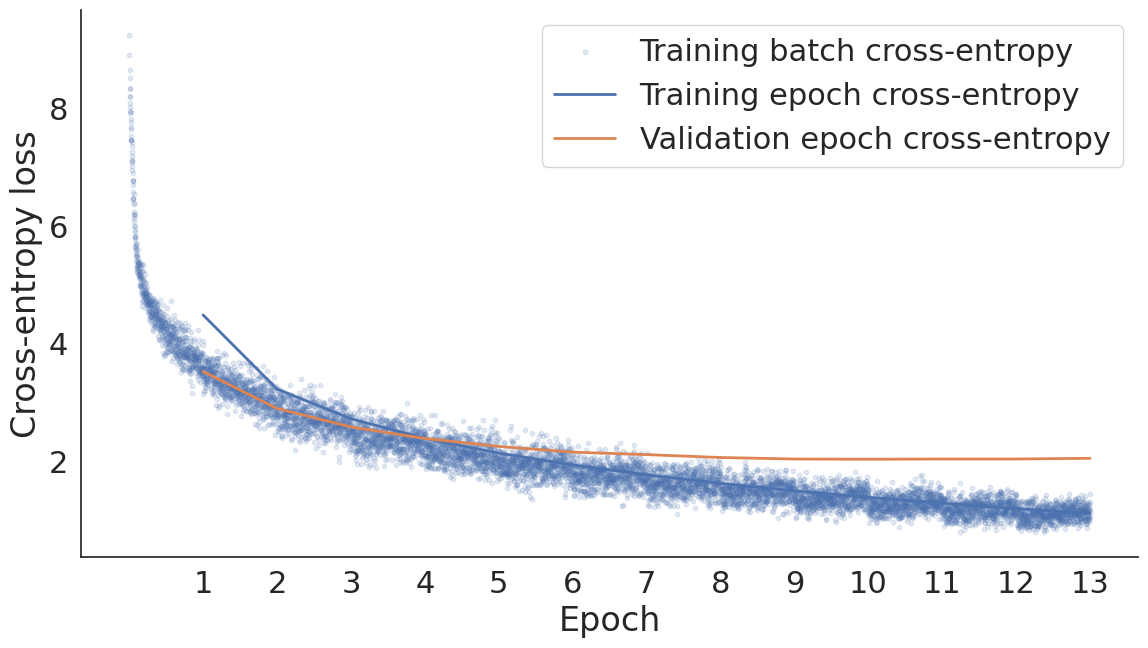

Final-epoch average training loss: 1.123
Final-epoch average validation loss: 2.059


In [18]:
# Plot the loss
steps_per_epoch = math.ceil(len(train_pairs) / BATCH_SIZE)
training_steps = (np.arange(len(train_loss_list)) + 1) / steps_per_epoch
plt.figure(figsize=(12, 7))
plt.scatter(training_steps, train_loss_list, s=10, alpha=0.15,
            label='Training batch cross-entropy')
plt.plot(range(1, NUM_EPOCHS + 1), train_epoch_losses, linewidth=2,
         label='Training epoch cross-entropy')
plt.plot(range(1, NUM_EPOCHS + 1), val_epoch_losses, linewidth=2,
         label='Validation epoch cross-entropy')
plt.xlabel('Epoch')
plt.ylabel('Cross-entropy loss')
plt.xticks(range(1, NUM_EPOCHS + 1))
plt.legend()
sns.despine()
plt.tight_layout()
plt.show()

print(f"Final-epoch average training loss: {train_epoch_losses[-1]:.3f}")
print(f"Final-epoch average validation loss: {val_epoch_losses[-1]:.3f}")

In [19]:
# Define a decode function to generate output sequence using greedy algorithm
# This basically saves us some compute time by taking a bunch of shortcuts (e.g. not computing the full softmax)
@torch.no_grad()
def greedy_decode(model, src, src_mask, max_len, start_symbol):
    src, src_mask = src.to(DEVICE), src_mask.to(DEVICE)
    memory = model.encode(src, src_mask)
    ys = torch.full((1, 1), start_symbol, dtype=torch.long, device=DEVICE)
    for _ in range(max_len - 1):
        tgt_mask = generate_square_subsequent_mask(ys.size(0))
        out = model.decode(ys, memory, tgt_mask)
        next_word = model.generator(out[-1, :, :]).argmax(dim=-1).item()
        ys = torch.cat((ys, torch.tensor([[next_word]], device=DEVICE, dtype=torch.long)), dim=0)
        if next_word == EOS_IDX:
            break
    return ys

# Define a translation function that actually uses the model to translate a sentence from source to target
@torch.no_grad()
def translate(model, src_sentence):
    model.eval()
    src = text_transform[SRC_LANGUAGE](src_sentence).view(-1, 1)
    src_mask = torch.zeros((src.size(0), src.size(0)), dtype=torch.bool, device=DEVICE)
    tgt_ids = greedy_decode(model, src, src_mask, max_len=src.size(0) + 5,
                            start_symbol=BOS_IDX).flatten().cpu().tolist()
    if tgt_ids and tgt_ids[0] == BOS_IDX:
        tgt_ids = tgt_ids[1:]
    if EOS_IDX in tgt_ids:
        tgt_ids = tgt_ids[:tgt_ids.index(EOS_IDX)]
    return ' '.join(vocab_transform[TGT_LANGUAGE].lookup_tokens(tgt_ids))

## Let's try the model out on a few of our test sequences. Print the first 10 target/translated sequences from our test set

In [21]:
for german, english in test_pairs[:10]:
    print(f"German input:   {german}")
    print(f"English target: {english}")
    print(f"Model output:   {translate(transformer, german)}")
    print()

German input:   Zwei Personen in schwarzen Hemden stehen vor Kindern in weißen Hemden mit einer amerikanischen Flagge.
English target: Two people in black vests are standing in front of children in white vests with an American flag between them.
Model output:   Two people in black shirts stand in front of children in white shirts with American flag .

German input:   Eine Gruppe von Einkäufern trotzt der Kälte, während einer auf sein Lieblingsgeschäft zeigt.
English target: A group of faithful shoppers bear the cold while one points to his favorite store.
Model output:   A group of college students are picking up the cold members of an art ride in their wedding .

German input:   Eine blonde Frau schenkt an einer Bar Getränke ein.
English target: A blond-haired woman is pouring drinks at a bar.
Model output:   A blond woman is pouring drinks at a bar .

German input:   Ein Kind berührt Teig auf einem Schneidbrett.
English target: A child is touching dough on a cutting board.
Model outp